# Convolutional Neural Network: classifying clothes

**Goal.** Use the spatial structure of an image.

**The model.** A small filter slides across the image, so one set of weights is reused everywhere (*weight sharing*).
Pooling shrinks the image while the number of filters grows, so later layers see larger patterns.

**The dataset.** *Fashion-MNIST* (Zalando): 70,000 grayscale images of 28x28 pixels in 10 clothing classes.

Using the same data as the MLP makes the comparison fair.

In [1]:
# SETUP: install any package this notebook needs but your Python does not have.
# It uses the same Python that runs this notebook, so it also works on Windows
# inside a virtual environment or Anaconda.
import importlib.util
import subprocess
import sys

required = {  # import name -> pip package name
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "sklearn": "scikit-learn",
    "torch": "torch",
    "certifi": "certifi"
}
missing = [pip for module, pip in required.items() if importlib.util.find_spec(module) is None]
if missing:
    print("Installing:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
else:
    print("All required packages are already installed.")

All required packages are already installed.


In [2]:
# A consistent look for every figure, and a fixed random seed so that
# running the notebook twice gives the same numbers.
import warnings
import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

PURPLE, BLUE, GREEN, ORANGE, RED = "#5A28C8", "#476ADD", "#00A651", "#F28C28", "#E0344B"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 12, "axes.titleweight": "bold", "axes.titlecolor": PURPLE,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})

## 1. Get the data

In [3]:
# DOWNLOAD THE DATASET
# Files are stored next to this notebook in a "data" folder, and are only
# downloaded the first time. pathlib builds correct paths on Windows.
#
# Why certifi? Some Windows machines have an out-of-date certificate store and
# fail with CERTIFICATE_VERIFY_FAILED. certifi ships an up-to-date list of trusted
# authorities, so the secure connection is still fully verified.
import shutil
import ssl
import urllib.request
import zipfile
from pathlib import Path

import certifi

def download(url, destination):
    """Download url to destination unless the file already exists."""
    destination = Path(destination)
    if destination.exists():
        print("Already downloaded:", destination)
        return destination
    destination.parent.mkdir(parents=True, exist_ok=True)
    print("Downloading:", url)
    context = ssl.create_default_context(cafile=certifi.where())
    request = urllib.request.Request(url, headers={"User-Agent": "python"})
    temporary = destination.with_suffix(destination.suffix + ".part")
    with urllib.request.urlopen(request, context=context, timeout=600) as response, open(temporary, "wb") as output:
        shutil.copyfileobj(response, output)
    temporary.replace(destination)  # only a complete file gets the final name
    print("Saved:", destination, f"({destination.stat().st_size / 1e6:.1f} MB)")
    return destination

import gzip

BASE = "https://github.com/zalandoresearch/fashion-mnist/raw/master/data/fashion/"
DATA_DIR = Path("data") / "fashion_mnist"
for name in ("train-images-idx3-ubyte.gz", "train-labels-idx1-ubyte.gz",
             "t10k-images-idx3-ubyte.gz", "t10k-labels-idx1-ubyte.gz"):
    download(BASE + name, DATA_DIR / name)

def read_images(path):
    with gzip.open(path, "rb") as f:   # the first 16 bytes are a header
        return np.frombuffer(f.read(), np.uint8, offset=16).reshape(-1, 28, 28)

def read_labels(path):
    with gzip.open(path, "rb") as f:   # the first 8 bytes are a header
        return np.frombuffer(f.read(), np.uint8, offset=8)

train_images = read_images(DATA_DIR / "train-images-idx3-ubyte.gz")
train_labels = read_labels(DATA_DIR / "train-labels-idx1-ubyte.gz")
test_images = read_images(DATA_DIR / "t10k-images-idx3-ubyte.gz")
test_labels = read_labels(DATA_DIR / "t10k-labels-idx1-ubyte.gz")
class_names = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Boot"]
print("Train:", train_images.shape, "Test:", test_images.shape)

Already downloaded: data\fashion_mnist\train-images-idx3-ubyte.gz
Already downloaded: data\fashion_mnist\train-labels-idx1-ubyte.gz
Already downloaded: data\fashion_mnist\t10k-images-idx3-ubyte.gz
Already downloaded: data\fashion_mnist\t10k-labels-idx1-ubyte.gz


Train: (60000, 28, 28) Test: (10000, 28, 28)


In [4]:
import torch
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Running on:", device)

# Scale pixels from 0-255 to 0-1, and add the channel dimension PyTorch expects: (N, 1, 28, 28).
to_tensor = lambda images: torch.tensor(images / 255.0, dtype=torch.float32).unsqueeze(1)
X, y = to_tensor(train_images), torch.tensor(train_labels, dtype=torch.long)
X_test, y_test = to_tensor(test_images), torch.tensor(test_labels, dtype=torch.long)

# Hold back the last 10% of the training set for validation.
order = torch.randperm(len(X), generator=torch.Generator().manual_seed(SEED))
split = int(len(X) * 0.9)
train_idx, val_idx = order[:split], order[split:]

# num_workers=0 is the safe choice on Windows: worker processes often fail inside notebooks there.
train_loader = DataLoader(TensorDataset(X[train_idx], y[train_idx]), batch_size=128, shuffle=True, num_workers=0)

Running on: cpu


## 2. Define the network
Image size through the network: 28x28 → 14x14 → 7x7, then flattened.

In [5]:
import torch.nn as nn

model = nn.Sequential(
    nn.Conv2d(1, 32, kernel_size=3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
    nn.Flatten(),
    nn.Dropout(0.3),
    nn.Linear(64 * 7 * 7, 128), nn.ReLU(),
    nn.Linear(128, 10),
).to(device)

n_params = sum(p.numel() for p in model.parameters())
print(model)
print("Trainable parameters:", f"{n_params:,}")

Sequential(
  (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU()
  (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (6): ReLU()
  (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (8): Flatten(start_dim=1, end_dim=-1)
  (9): Dropout(p=0.3, inplace=False)
  (10): Linear(in_features=3136, out_features=128, bias=True)
  (11): ReLU()
  (12): Linear(in_features=128, out_features=10, bias=True)
)
Trainable parameters: 421,834


## 3. Train
On a CPU, this takes several minutes. Reduce `EPOCHS` for a faster experiment.

In [6]:
EPOCHS = 8

import copy
import time

def accuracy_of(model, inputs, targets, batch_size=1000):
    """Accuracy on a whole tensor, in batches, with gradients switched off."""
    model.eval()
    with torch.no_grad():
        predictions = torch.cat([model(inputs[i:i + batch_size].to(device)).argmax(1).cpu()
                                 for i in range(0, len(inputs), batch_size)])
    return float((predictions == targets).float().mean()), predictions

loss_fn = nn.CrossEntropyLoss()   # applies softmax internally, so the model outputs raw logits
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
history = {"train_loss": [], "val_acc": []}
best_val, best_state = 0.0, None

start = time.time()
for epoch in range(1, EPOCHS + 1):
    model.train()
    total = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()            # 1. forget gradients from the previous batch
        loss = loss_fn(model(xb), yb)    # 2. forward pass and error
        loss.backward()                  # 3. backpropagation computes the gradients
        optimizer.step()                 # 4. update the weights
        total += loss.item() * len(xb)

    val_acc, _ = accuracy_of(model, X[val_idx], y[val_idx])
    history["train_loss"].append(total / len(train_idx))
    history["val_acc"].append(val_acc)
    if val_acc > best_val:               # remember the best model seen so far
        best_val, best_state = val_acc, copy.deepcopy(model.state_dict())
    print(f"Epoch {epoch:2d}  train loss {history['train_loss'][-1]:.4f}  val accuracy {val_acc:.4f}")

train_seconds = time.time() - start
model.load_state_dict(best_state)

Epoch  1  train loss 0.4127  val accuracy 0.8940


Epoch  2  train loss 0.2886  val accuracy 0.9017


Epoch  3  train loss 0.2487  val accuracy 0.9045


Epoch  4  train loss 0.2257  val accuracy 0.9143


Epoch  5  train loss 0.2073  val accuracy 0.9195


Epoch  6  train loss 0.1923  val accuracy 0.9188


Epoch  7  train loss 0.1768  val accuracy 0.9168


Epoch  8  train loss 0.1629  val accuracy 0.9243


<All keys matched successfully>

## 4. Evaluate on the test set

In [7]:
from sklearn.metrics import confusion_matrix

test_acc, predictions = accuracy_of(model, X_test, y_test)
cm = confusion_matrix(y_test, predictions)
per_class = cm.diagonal() / cm.sum(axis=1)
print(f"Test accuracy: {test_acc:.4f} | Training time: {train_seconds:.0f} s")
print("Hardest class:", class_names[int(per_class.argmin())], round(float(per_class.min()), 3))

Test accuracy: 0.9187 | Training time: 718 s
Hardest class: Shirt 0.754


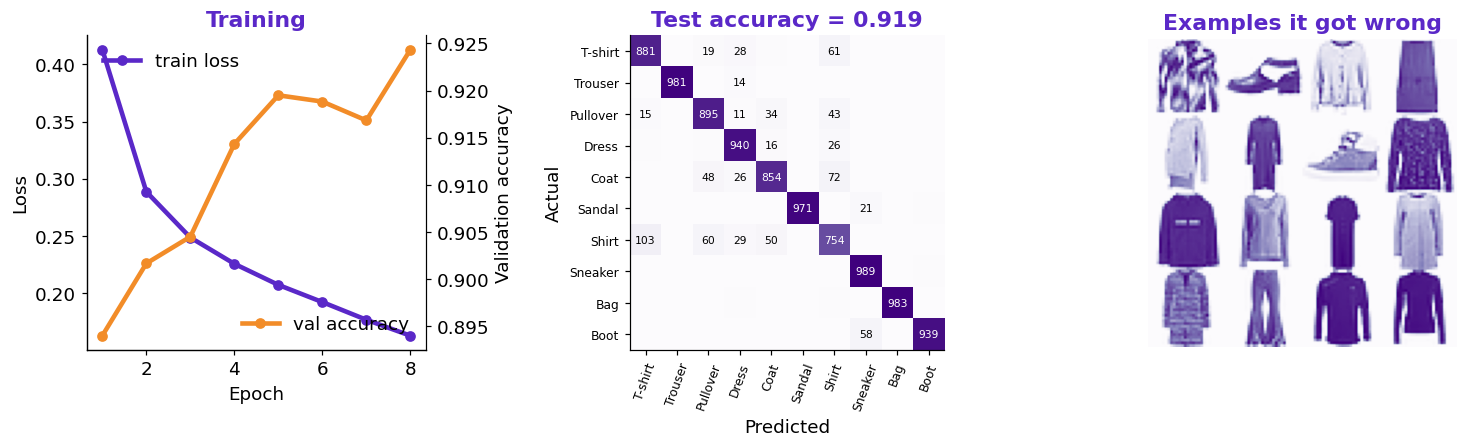

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(13.5, 4.2), gridspec_kw={"width_ratios": [1.1, 1.1, 1]})
ax[0].plot(range(1, EPOCHS + 1), history["train_loss"], color=PURPLE, lw=3, marker="o", label="train loss")
ax[0].set(title="Training", xlabel="Epoch", ylabel="Loss")
twin = ax[0].twinx()
twin.plot(range(1, EPOCHS + 1), history["val_acc"], color=ORANGE, lw=3, marker="o", label="val accuracy")
twin.spines["right"].set_visible(True)
twin.set_ylabel("Validation accuracy")
ax[0].legend(loc="upper left"); twin.legend(loc="lower right")

ax[1].imshow(cm, cmap="Purples")
for (i, j), v in np.ndenumerate(cm):
    if v >= 10:
        ax[1].text(j, i, v, ha="center", va="center", fontsize=7, color="white" if v > cm.max() / 2 else "black")
ax[1].set(title=f"Test accuracy = {test_acc:.3f}", xticks=range(10), yticks=range(10), xlabel="Predicted", ylabel="Actual")
ax[1].set_xticklabels(class_names, rotation=70, fontsize=8); ax[1].set_yticklabels(class_names, fontsize=8)

# A montage of mistakes.
wrong = np.where(predictions.numpy() != test_labels)[0][:16]
montage = np.vstack([np.hstack([test_images[i] for i in wrong[r * 4:(r + 1) * 4]]) for r in range(4)])
ax[2].imshow(montage, cmap="Purples")
ax[2].set(title="Examples it got wrong")
ax[2].axis("off")
fig.tight_layout()
plt.show()

In [9]:
# SAVE THE RESULTS. The figure and the metrics are written to a "results" folder.
# These exact files are what the course slides show.
import json

results_dir = Path("results")
results_dir.mkdir(exist_ok=True)
fig.savefig(results_dir / "02_cnn.png", dpi=170, bbox_inches="tight", facecolor="white")

results = {
    "model": "CNN",
    "dataset": "Fashion-MNIST",
    "n_samples": int(len(train_images) + len(test_images)),
    "metrics": {"Test accuracy": round(test_acc, 4), "Parameters": n_params, "Train time (s)": round(train_seconds), "Epochs": EPOCHS},
}
(results_dir / "02_cnn.json").write_text(json.dumps(results, indent=2), encoding="utf-8")
print(json.dumps(results, indent=2))

{
  "model": "CNN",
  "dataset": "Fashion-MNIST",
  "n_samples": 70000,
  "metrics": {
    "Test accuracy": 0.9187,
    "Parameters": 421834,
    "Train time (s)": 718,
    "Epochs": 8
  }
}


## What to remember
- Convolution exploits the fact that neighboring pixels are related.
- The hardest class is usually *Shirt*, which looks like T-shirt, Pullover and Coat.